# Introduction to Machine Learning – Lab 3
## Comparison of the Four Data Preparations

### Objective
Notebooks 08, 08.1, 08.2 and 08.3 cluster the same houses after four different preparations: min-max or z-score scaling, each with and without the logarithm of four columns. This notebook puts the results next to each other and explains how they differ and why. It does not pick a winner.

In [1]:
import sys
from itertools import combinations
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from clustering import (
    INK,
    N_INIT,
    THRESHOLDS,
    agreement_table,
    fit_models,
    inertia_table,
    plot_clusters,
    plot_preparation_curves,
    plot_variance_shares,
    reduce_to_thresholds,
    relabel,
    variance_by_type,
)
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import StrMethodFormatter
from preprocessing import (
    LOG_FEATURES,
    ORDINAL,
    drop_incomplete,
    fill_missing,
    log_features,
    make_preprocessor,
    make_scaler,
    make_zscore_scaler,
    prepare_data,
)
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

### The four prepared datasets

In [2]:
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
X_complete, y_complete = drop_incomplete(X, y)
X_complete = fill_missing(X_complete)
encoded_complete = make_preprocessor("onehot", min_frequency=5).fit_transform(X_complete, y_complete)

onehot = [col for col in encoded_complete.columns if col not in X_complete.columns]
ordinal = [col for col in encoded_complete.columns if col in ORDINAL]
numeric = [col for col in encoded_complete.columns if col not in onehot + ordinal]
column_types = {"One-hot": onehot, "Ordinal": ordinal, "Numeric": numeric}

assert encoded_complete.isna().sum().sum() == 0
assert len(onehot) + len(ordinal) + len(numeric) == encoded_complete.shape[1]

print(f"{len(encoded_complete):,} houses, {encoded_complete.shape[1]} columns")
print(f"One-hot: {len(onehot)}, ordinal: {len(ordinal)}, numeric: {len(numeric)}")

columns = encoded_complete.columns
scaled_columns = ordinal + numeric
logged = log_features(encoded_complete)

# Fitted on all houses: k-means has no train/test split.
# The z-score transformer moves the scaled columns to the front, so the original order is restored
prepared = {
    "Min-max": make_scaler().fit_transform(encoded_complete),
    "Z-score": make_zscore_scaler(scaled_columns).fit_transform(encoded_complete)[columns],
    "Min-max + log": make_scaler().fit_transform(logged),
    "Z-score + log": make_zscore_scaler(scaled_columns).fit_transform(logged)[columns],
}

for name, data in prepared.items():
    print(f"{name}: {data.shape[0]:,} x {data.shape[1]}, values from {data.min().min():.1f} to {data.max().max():.1f}")

2,923 houses, 205 columns
One-hot: 151, ordinal: 21, numeric: 33
Min-max: 2,923 x 205, values from 0.0 to 1.0
Z-score: 2,923 x 205, values from -10.3 to 32.7
Min-max + log: 2,923 x 205, values from 0.0 to 1.0
Z-score + log: 2,923 x 205, values from -10.3 to 32.7


### Variance by column type

,One-hot,Ordinal,Numeric
Min-max,0.825,0.092,0.083
Z-score,0.134,0.337,0.529
Min-max + log,0.816,0.091,0.093
Z-score + log,0.134,0.337,0.529


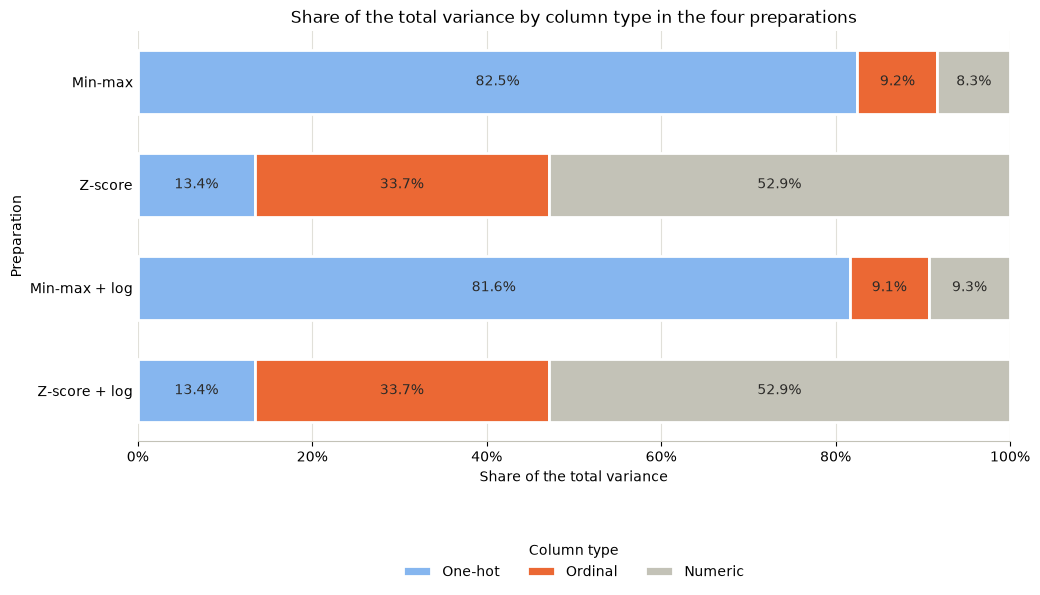

Share of the total variance held by the four log columns:
Min-max          0.4%
Z-score          6.4%
Min-max + log    1.5%
Z-score + log    6.4%


In [3]:
variance_shares = pd.DataFrame({name: variance_by_type(data, column_types) for name, data in prepared.items()}).T
log_column_share = pd.Series({name: data[LOG_FEATURES].var().sum() / data.var().sum() for name, data in prepared.items()})

display(variance_shares.round(3))
plot_variance_shares(variance_shares, "Share of the total variance by column type in the four preparations")
print("Share of the total variance held by the four log columns:")
print(log_column_share.map("{:.1%}".format).to_string())

#### Interpretation of the variance by column type
- **Why this matters first:** PCA and k-means both work with squared distances, so a column counts as much as its variance. The share of the variance tells which columns steer the results.
- **Min-max:** the one-hot columns hold 82.5%. A 0/1 column uses the whole range from 0 to 1, while a numeric column is squeezed by its most extreme house, so most of its values lie close together. There are also 151 one-hot columns against 54 others.
- **Z-score:** each of the 54 ordinal and numeric columns has variance 1, while the one-hot columns keep their small variance at 0/1. The shares turn around: 13.4% one-hot, 33.7% ordinal and 52.9% numeric.
- **Log under min-max:** the numeric share rises from 8.3% to 9.3%, because the logarithm spreads houses that were squeezed together. The four log columns go from 0.4% to 1.5% of the variance.
- **Log under z-score:** nothing changes, as the columns return to variance 1. The four log columns hold 6.4% with and without the logarithm, and only their shape differs.

### Principal components

In [4]:
fits = {name: reduce_to_thresholds(data) for name, data in prepared.items()}

rows = []
for name, (pca, reduced, counts) in fits.items():
    first_component = pd.Series(pca.components_[0], index=columns)
    top_columns = first_component.abs().nlargest(6).index
    rows.append(
        {
            "Preparation": name,
            **{f"Components at {t:.0%}": count for t, count in counts.items()},
            "PC1": f"{pca.explained_variance_ratio_[0]:.2%}",
            "PC2": f"{pca.explained_variance_ratio_[1]:.2%}",
            "Squared PC1 weights in one-hot columns": f"{(first_component[onehot] ** 2).sum():.1%}",
            "Top PC1 columns": ", ".join(top_columns),
        }
    )

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Preparation").T)

Preparation,Min-max,Z-score,Min-max + log,Z-score + log
Components at 98%,113,84,113,84
Components at 95%,82,61,82,61
Components at 90%,59,45,59,45
Components at 80%,36,30,36,29
PC1,13.40%,18.33%,13.53%,18.68%
PC2,8.86%,6.91%,8.80%,6.90%
Squared PC1 weights in one-hot columns,73.7%,6.0%,72.0%,5.9%
Top PC1 columns,"Foundation_PConc, Exterior 1st_VinylSd, Exterior 2nd_VinylSd, Garage Type_Attchd, Garage Type_Detchd, Year Remod/Add","Overall Qual, Garage Cars, Year Built, Garage Yr Blt, Exter Qual, Garage Area","Foundation_PConc, Exterior 1st_VinylSd, Exterior 2nd_VinylSd, Garage Type_Attchd, Garage Type_Detchd, Year Remod/Add","Overall Qual, Garage Cars, Year Built, Garage Yr Blt, Exter Qual, Garage Area"


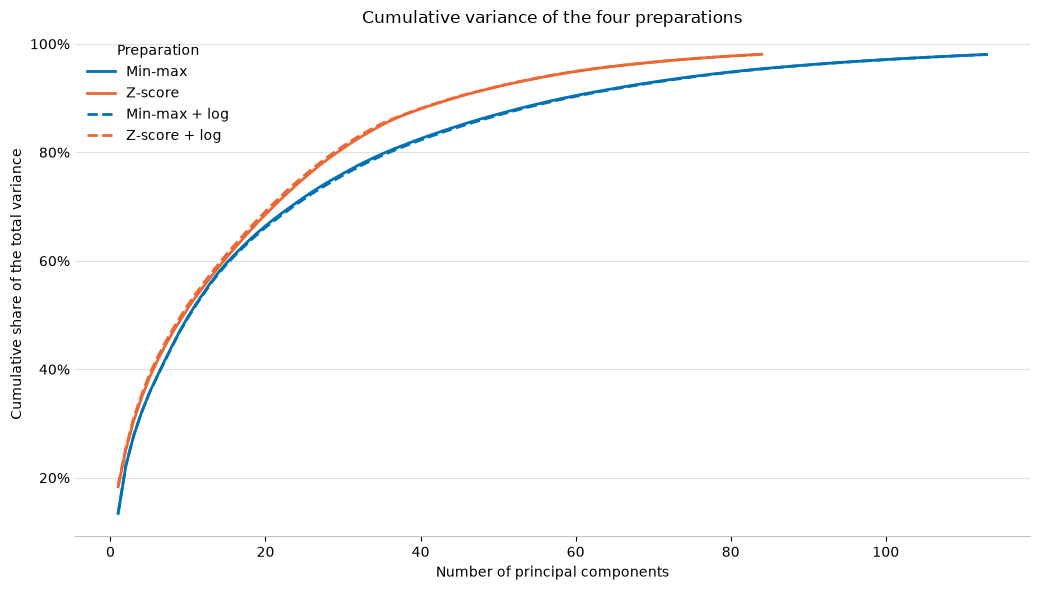

In [5]:
curves = {
    name: pd.Series(pca.explained_variance_ratio_.cumsum(), index=range(1, pca.n_components_ + 1))
    for name, (pca, _, _) in fits.items()
}

fig, ax = plot_preparation_curves(
    curves,
    "Cumulative variance of the four preparations",
    "Number of principal components",
    "Cumulative share of the total variance",
)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0%}"))
plt.tight_layout()
plt.show()

#### Interpretation of the principal components
- **Number of components:** z-score needs fewer components at each threshold, for example 45 against 59 at 90%. Most of its variance sits in 54 columns, many of which measure related things such as quality, size and age, while under min-max it is spread over the 151 one-hot columns. The curves show this as a faster rise of the orange lines.
- **Log changes almost nothing here:** the dashed lines lie on the solid ones, and only one count differs: 29 instead of 30 components at 80% for z-score + log. PC1 moves from 13.40% to 13.53% and from 18.33% to 18.68%.
- **Min-max:** building-type columns lead PC1, namely `Foundation_PConc`, `Exterior 1st_VinylSd`, `Exterior 2nd_VinylSd`, `Garage Type_Attchd` and `Garage Type_Detchd`. The squared weights of a component add up to 1, so they show how much of it is built from a group of columns, and the one-hot columns make up 73.7% of PC1.
- **Z-score:** the leaders are `Overall Qual`, `Garage Cars`, `Year Built`, `Garage Yr Blt`, `Exter Qual` and `Garage Area`, so quality, size (of the garage, in these six) and age. The one-hot columns make up only 6.0% of PC1.
- **Meaning:** PC1 follows the columns that hold the variance, so the two scalings give PC1 a different content. The logarithm keeps the top six columns of each scaling.

### Elbow curves at 90% of the variance

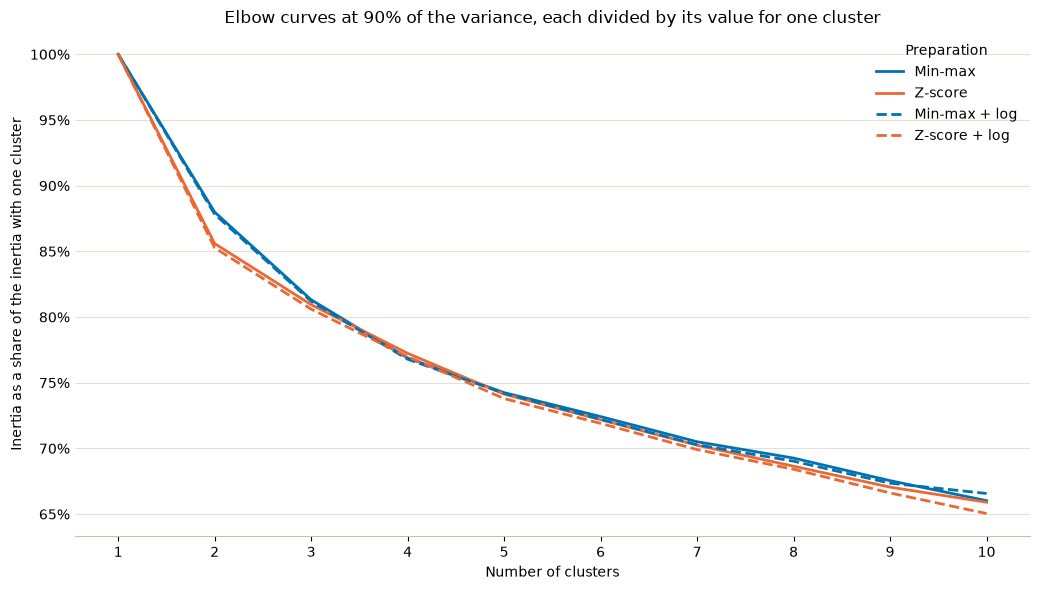

Inertia with one cluster:
Min-max           26796.0
Z-score          164629.0
Min-max + log     27043.0
Z-score + log    164748.0
Percentage drop in inertia when one more cluster is added:


,Min-max,Z-score,Min-max + log,Z-score + log
Cluster added,,,,
2,12.0,14.4,12.2,14.7
3,7.6,5.4,7.5,5.5
4,5.4,4.6,5.4,4.5
5,3.4,4.0,3.4,4.1
6,2.5,2.6,2.7,2.6
7,2.6,2.7,2.7,2.8
8,1.8,2.3,1.8,2.1
9,2.5,2.3,2.4,2.6
10,2.3,1.7,1.2,2.4


In [6]:
inertia = pd.DataFrame(
    {
        name: inertia_table(reduced, {0.90: counts[0.90]}, range(1, 11))["90%"]
        for name, (_, reduced, counts) in fits.items()
    }
)
relative_inertia = inertia / inertia.loc[1]
drop_per_cluster = inertia.pct_change().dropna().mul(-100).round(1)
drop_per_cluster.index.name = "Cluster added"

fig, ax = plot_preparation_curves(
    relative_inertia,
    "Elbow curves at 90% of the variance, each divided by its value for one cluster",
    "Number of clusters",
    "Inertia as a share of the inertia with one cluster",
)
ax.set_xticks(relative_inertia.index)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0%}"))
plt.tight_layout()
plt.show()

print("Inertia with one cluster:")
print(inertia.loc[1].round(0).to_string())
print("Percentage drop in inertia when one more cluster is added:")
display(drop_per_cluster)

#### Interpretation of the elbow curves
- **Different units:** with one cluster, inertia is about 26,800 for min-max and 164,600 for z-score. A min-max distance is a share of a column's range, and a z-score distance is counted in standard deviations. The same applies to the distances behind the silhouette. Across the two scalings, only the shape of a curve and the rough size of a score can be compared, never the raw values.
- **Common axis:** dividing by the value at one cluster makes all curves start at 100%, so their shapes can be laid on top of each other.
- **Scaling:** z-score has the larger first drop, 14.4% against 12.0%, followed by a smaller second one, 5.4% against 7.6%. So its bend at 2 clusters is sharper, while min-max bends more evenly.
- **After 5 clusters:** all four curves flatten at the same place. The fifth cluster removes between 3.4% and 4.1%, and the sixth between 2.5% and 2.7%.
- **Log:** each dashed line stays close to its solid line. The one visible gap is at 10 clusters for min-max + log, 1.2% against 2.3%, a single step of the kind that k-means also shows elsewhere and no general pattern.

### Clusters at 5 clusters and 90% of the variance

In [7]:
n_clusters = 5
models = {name: fit_models(reduced, counts, n_clusters) for name, (_, reduced, counts) in fits.items()}

rows = []
for name, (_, reduced, counts) in fits.items():
    model = models[name][0.90]
    values = silhouette_samples(reduced[:, : counts[0.90]], model.labels_)
    sizes = np.bincount(model.labels_)
    rows.append(
        {
            "Preparation": name,
            "Cluster sizes": sorted(sizes.tolist()),
            "Smallest cluster": sizes.min() / sizes.sum(),
            "Average silhouette": values.mean(),
            "Negative silhouette": (values < 0).mean(),
        }
    )

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("Preparation").round(3))

,Cluster sizes,Smallest cluster,Average silhouette,Negative silhouette
Preparation,,,,
Min-max,"[531, 549, 555, 601, 687]",0.182,0.110,0.169
Z-score,"[166, 588, 652, 657, 860]",0.057,0.097,0.070
Min-max + log,"[528, 556, 558, 593, 688]",0.181,0.109,0.168
Z-score + log,"[165, 572, 654, 659, 873]",0.056,0.096,0.070


#### Interpretation of the clusters
- **Sizes:** min-max gives five groups of similar size, the smallest holding 18.2% of the houses. Z-score gives one small group of 166 houses (5.7%) next to groups of up to 860. Under z-score the ordinal and numeric columns hold most of the variance, so a small group that sits far from the others in several of these columns at once can form a cluster of its own. Under min-max the same columns hold little variance, so such a group does not stand out.
- **Silhouette:** the averages are close, 0.110 and 0.109 for min-max against 0.097 and 0.096 for z-score. All are low, so the clusters overlap under every preparation.
- **Negative silhouettes:** only 7.0% of the houses are negative under z-score, against 16.9% and 16.8% under min-max. So z-score has a lower average with fewer misplaced houses, and the two scores do not point the same way. As the distances are in different units, neither number shows that one preparation is better.
- **Log:** compared in order of size, the clusters change by at most 8 houses under min-max (601 and 593) and by at most 16 under z-score (588 and 572).

### Agreement between the groupings

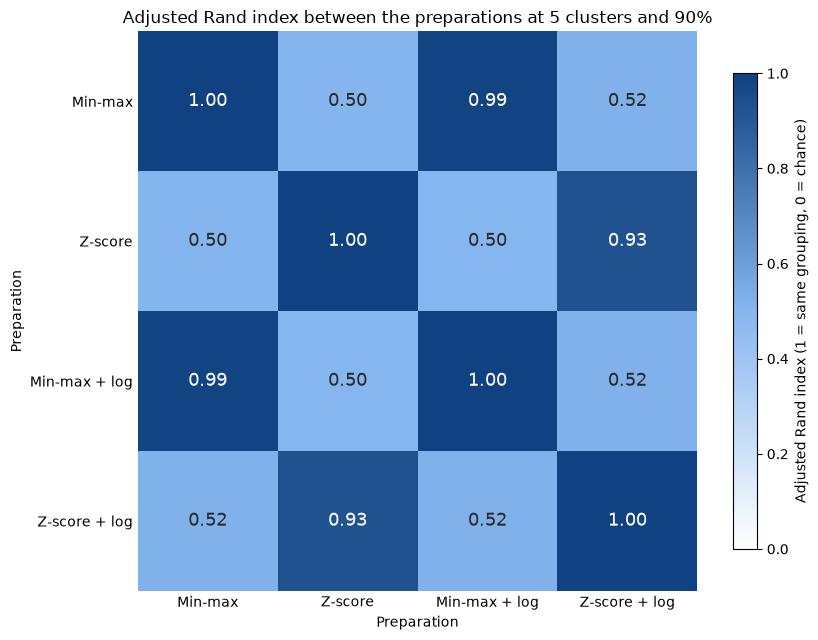

,Min-max,Z-score,Min-max + log,Z-score + log
Min-max,1.000,0.501,0.986,0.519
Z-score,0.501,1.000,0.500,0.927
Min-max + log,0.986,0.500,1.000,0.519
Z-score + log,0.519,0.927,0.519,1.000


In [8]:
labels_at_90 = {name: per_threshold[0.90].labels_ for name, per_threshold in models.items()}
agreement = agreement_table(labels_at_90)

blues = LinearSegmentedColormap.from_list("agreement", ["#ffffff", "#86b6ef", "#104281"])
fig, ax = plt.subplots(figsize=(8.5, 6.5))
image = ax.imshow(agreement, cmap=blues, vmin=0, vmax=1)
for row, name in enumerate(agreement.index):
    for column, value in enumerate(agreement.loc[name]):
        color = "white" if value > 0.7 else INK
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color=color, fontsize=13)
ax.set_xticks(range(len(agreement)), agreement.columns)
ax.set_yticks(range(len(agreement)), agreement.index)
ax.set_title("Adjusted Rand index between the preparations at 5 clusters and 90%", fontsize=12)
ax.set_xlabel("Preparation")
ax.set_ylabel("Preparation")
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
fig.colorbar(image, ax=ax, label="Adjusted Rand index (1 = same grouping, 0 = chance)", shrink=0.85)
plt.tight_layout()
plt.show()

display(agreement.round(3))

In [9]:
rows = []
for name, per_threshold in models.items():
    table = agreement_table({f"{t:.0%}": model.labels_ for t, model in per_threshold.items()})
    pair_scores = table.to_numpy()[np.triu_indices(len(table), k=1)]
    rows.append({"Preparation": name, "Lowest agreement": pair_scores.min(), "Highest agreement": pair_scores.max()})

print("Agreement between the thresholds of each preparation:")
display(pd.DataFrame(rows).set_index("Preparation").round(3))

Agreement between the thresholds of each preparation:


,Lowest agreement,Highest agreement
Preparation,,
Min-max,0.983,0.996
Z-score,0.951,0.995
Min-max + log,0.980,0.992
Z-score + log,0.965,0.997


#### Interpretation of the agreement
- **Reading the heatmap:** the adjusted Rand index compares two groupings of the same houses, ignoring cluster numbers. 1 means the same grouping and 0 means no more agreement than chance.
- **Between the scalings:** 0.50 to 0.52 in all four cells that pair a min-max with a z-score preparation. This lies well above chance, so the groupings share a real part, but they are clearly different groups.
- **Log:** 0.99 under min-max and 0.93 under z-score. The logarithm moves a few houses under min-max and somewhat more under z-score, where the four log columns hold 6.4% of the variance instead of 1.5%.
- **Thresholds:** within one preparation the lowest agreement is between 0.951 and 0.983, so the choice of threshold matters little. Z-score has the widest range, 0.951 to 0.995.

### Clusters drawn on PC1 and PC2

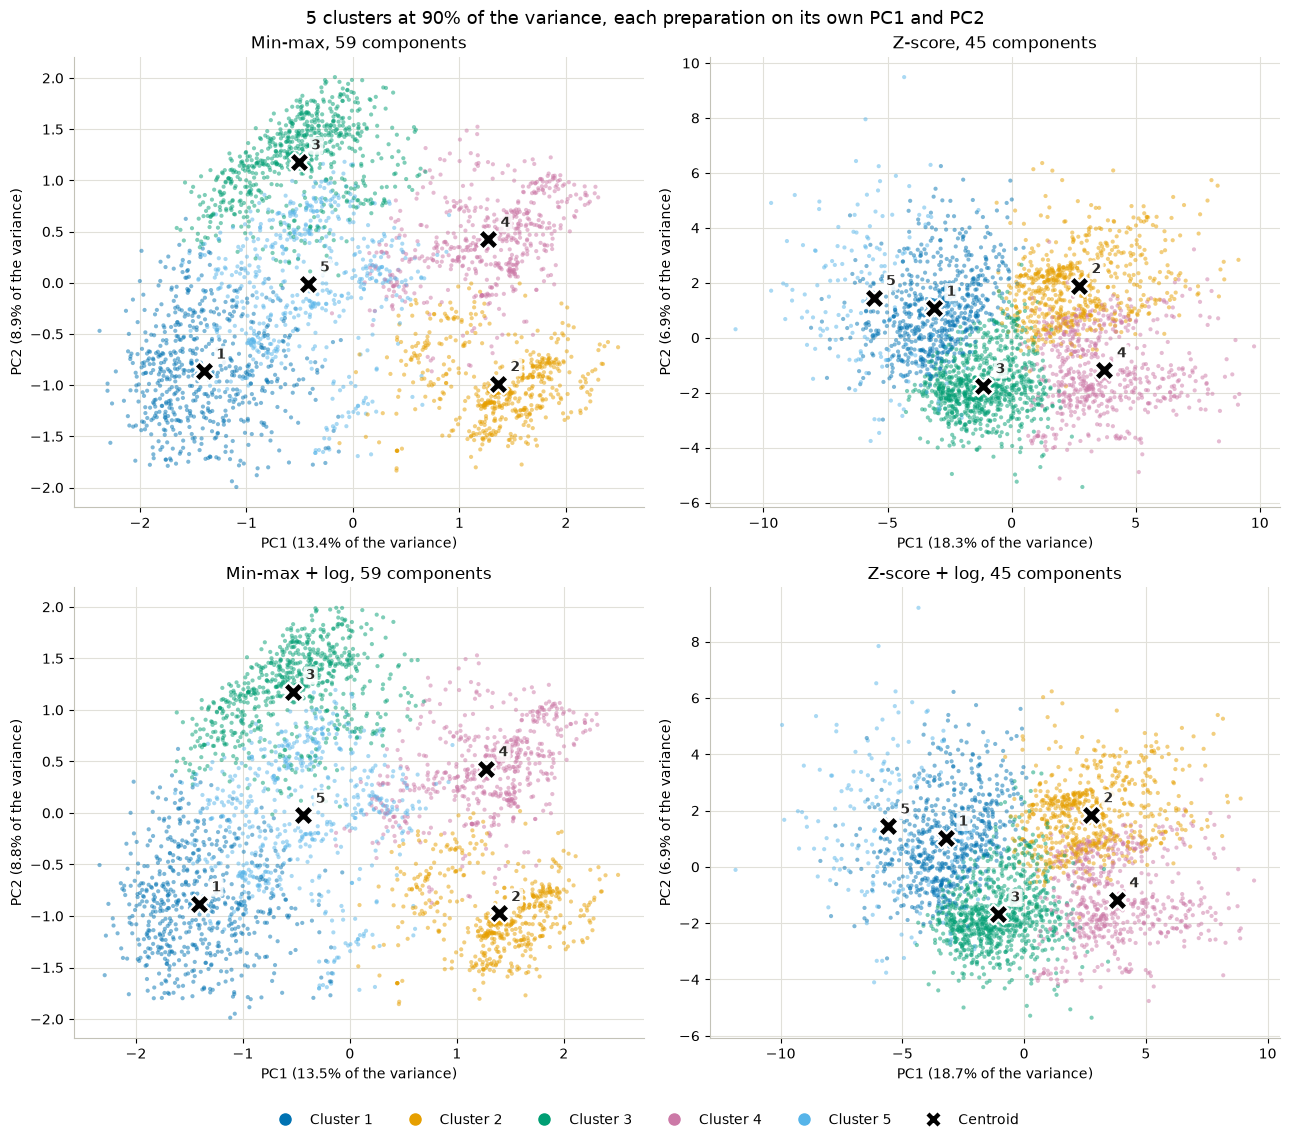

In [10]:
reference = models["Min-max"][0.90].labels_

panels = {
    f"{name}, {counts[0.90]} components": (pca, reduced, relabel(models[name][0.90], reference))
    for name, (pca, reduced, counts) in fits.items()
}
plot_clusters(panels, "5 clusters at 90% of the variance, each preparation on its own PC1 and PC2", shared_axes=False)

#### Interpretation of the scatter plots
- **Own axes:** each panel has its own axes because PC1 and PC2 are different mixes of columns in each preparation, and the two scalings also differ in units: about -2 to 2 on PC1 for min-max and about -10 to 10 for z-score. Positions cannot be compared between the two scalings, only the overall shape.
- **Shape of the cloud:** under min-max the houses form uneven clumps, because 0/1 columns drive PC1 and PC2, and houses with the same categories land near each other. Under z-score the houses form one rounder cloud, because many graded and measured columns add up smoothly.
- **Colors:** the clusters of each preparation are numbered to overlap the min-max clusters as far as possible. With an agreement of about 0.5 this match is only partial for the two z-score panels, so the same color does not mean the same houses there.
- **Log:** within each column of the figure, the upper and the lower panel look almost the same. The clusters and centroids stay in nearly the same places.

### What changes the clusters most

In [11]:
comparisons = [
    ("Scaling", "Min-max", "Z-score"),
    ("Scaling", "Min-max + log", "Z-score + log"),
    ("Log", "Min-max", "Min-max + log"),
    ("Log", "Z-score", "Z-score + log"),
]

rows = []
for change, first, second in comparisons:
    for threshold in THRESHOLDS:
        score = adjusted_rand_score(models[first][threshold].labels_, models[second][threshold].labels_)
        rows.append({"Change": change, "Compared": f"{first} / {second}", "Agreement": score})
for name, per_threshold in models.items():
    for first, second in combinations(per_threshold.values(), 2):
        score = adjusted_rand_score(first.labels_, second.labels_)
        rows.append({"Change": "Threshold", "Compared": name, "Agreement": score})

for name, (_, reduced, counts) in fits.items():
    runs = [
        KMeans(n_clusters=n_clusters, n_init=N_INIT, random_state=seed).fit_predict(reduced[:, : counts[0.90]])
        for seed in range(6)
    ]
    for first, second in combinations(runs, 2):
        rows.append({"Change": "Seed only", "Compared": name, "Agreement": adjusted_rand_score(first, second)})

effects = pd.DataFrame(rows)
statistics = ["count", "mean", "min", "max"]
display(effects.groupby("Change", sort=False)["Agreement"].agg(statistics).round(3))
display(effects.groupby(["Change", "Compared"], sort=False)["Agreement"].agg(statistics).round(3))

rank_correlation = [spearmanr(encoded_complete[col], logged[col]).statistic for col in LOG_FEATURES]
print(f"Columns changed by the logarithm: {len(LOG_FEATURES)} of {len(columns)}")
print(f"Lowest rank correlation of a log column with its raw values: {min(rank_correlation):.3f}")

,count,mean,min,max
Change,,,,
Scaling,8,0.511,0.500,0.525
Log,8,0.960,0.927,0.992
Threshold,24,0.981,0.951,0.997
Seed only,60,0.966,0.727,1.000


count   mean    min    max
Change    Compared                                                 
Scaling   Min-max / Z-score                  4  0.502  0.500  0.507
          Min-max + log / Z-score + log      4  0.520  0.513  0.525
Log       Min-max / Min-max + log            4  0.984  0.971  0.992
          Z-score / Z-score + log            4  0.936  0.927  0.954
Threshold Min-max                            6  0.987  0.983  0.996
          Z-score                            6  0.971  0.951  0.995
          Min-max + log                      6  0.987  0.980  0.992
          Z-score + log                      6  0.979  0.965  0.997
Seed only Min-max                           15  0.992  0.982  0.998
          Z-score                           15  0.979  0.962  1.000
          Min-max + log                     15  0.902  0.727  0.997
          Z-score + log                     15  0.992  0.985  1.000

Columns changed by the logarithm: 4 of 205
Lowest rank correlation of a log column with its raw values: 1.000


#### Interpretation of the differences
- **Ranking:** the scaling changes the clusters most by far, then the logarithm, then the threshold. The mean agreement is 0.511 between the scalings (0.500 to 0.525), 0.960 with and without log (0.927 to 0.992) and 0.981 between thresholds (0.951 to 0.997).
- **How firm that order is:** the first place is beyond doubt, while the gap between log and threshold is small. Under min-max the two are practically tied, with means of 0.984 for log and 0.987 for the thresholds. Under z-score the logarithm has the clearly larger effect, 0.936 against 0.971 and 0.979.
- **Seed as a yardstick:** a new seed alone gives a mean agreement of 0.992, 0.979, 0.902 and 0.992 in the four preparations. So the effect of the thresholds, and of the logarithm under min-max, are about as large as the random start. Only the scaling and the logarithm under z-score go clearly beyond it. The low minimum of 0.727 for min-max + log comes from the seed 0 run, as notebook 08.2 shows.
- **Why the scaling matters most:** it decides which columns hold the variance, and k-means follows the variance. Under min-max the one-hot columns hold 82.5%, so building-type columns lead PC1 and distances mainly reflect which categories a house has. Under z-score the ordinal and numeric columns hold 33.7% and 52.9%, so quality, size and age lead. These are two different questions about the same houses, which explains an agreement of only about 0.5.
- **Why the logarithm matters less:** it changes 4 of the 205 columns and keeps the order of the houses inside them, as the rank correlation of 1.000 shows. Close houses mostly stay close, and only houses near a border can switch. Its effect is larger under z-score because the four columns hold 6.4% of the variance there, against 1.5% under min-max, and because their most extreme houses sit many standard deviations out before the logarithm, as notebook 08.3 shows.
- **Why the threshold matters least:** the four datasets of a preparation share their first components, and the components that differ hold little variance. Most of the distance between two houses is the same in all four datasets.
- **Limits:** these numbers show how far the groupings differ, not which of them is better. Inertia and silhouette are not comparable across the scalings, and the silhouette of every preparation stays near 0.1.